# Inventory Visualizations Project
This notebook contains the segmented parts of our data loading, preparation, and 12 distinct visualizations analyzing inventory priorities.

## 1. Install and Load Packages

In [20]:
packages <- c("ggplot2", "dplyr", "tidyr", "scales", "treemapify")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}

library(ggplot2)
library(dplyr)
library(tidyr)
library(scales)
library(treemapify)

## 2. Load Datasets

In [21]:
priority_category <- read.csv(
  "/content/priority_by_category.csv",
  stringsAsFactors = FALSE
)

priority_summary <- read.csv(
  "/content/priority_summary.csv",
  stringsAsFactors = FALSE
)

inventory <- read.csv(
  "/content/inventory_priority.csv",
  stringsAsFactors = FALSE
)

cat("All datasets loaded successfully!\n\n")
cat("Priority by Category:", nrow(priority_category), "records\n")
cat("Priority Summary:", nrow(priority_summary), "records\n")
cat("Inventory Priority:", nrow(inventory), "records\n")

All datasets loaded successfully!

Priority by Category: 72 records
Priority Summary: 3 records
Inventory Priority: 118 records


## 3. Data Preparation & Common Theme

In [22]:
priority_colors <- c(
  "High" = "#16A085",
  "Medium" = "#F4B942",
  "Low" = "#E76F51"
)

priority_order <- c("Low", "Medium", "High")

priority_category$inventory_priority <- factor(
  priority_category$inventory_priority,
  levels = priority_order
)

priority_summary$inventory_priority <- factor(
  priority_summary$inventory_priority,
  levels = priority_order
)

inventory$inventory_priority <- factor(
  inventory$inventory_priority,
  levels = priority_order
)

category_data <- priority_category %>%
  group_by(category_name, inventory_priority) %>%
  summarise(
    product_count = sum(product_count, na.rm = TRUE),
    .groups = "drop"
)

inventory <- inventory %>%
  filter(
    !is.na(total_sales),
    !is.na(total_quantity),
    !is.na(average_sales),
    total_sales >= 0,
    total_quantity >= 0
  )

my_theme <- theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(
      color = "#64748B", size = 10
    ),
    axis.title = element_text(
      face = "bold", color = "#334155"
    ),
    axis.text = element_text(color = "#475569"),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(
      color = "#E2E8F0", linewidth = 0.4
    ),
    legend.title = element_text(face = "bold"),
    plot.background = element_rect(
      fill = "white", color = NA
    )
  )

### Chart 1: Inventory Priority Distribution (Donut Chart)

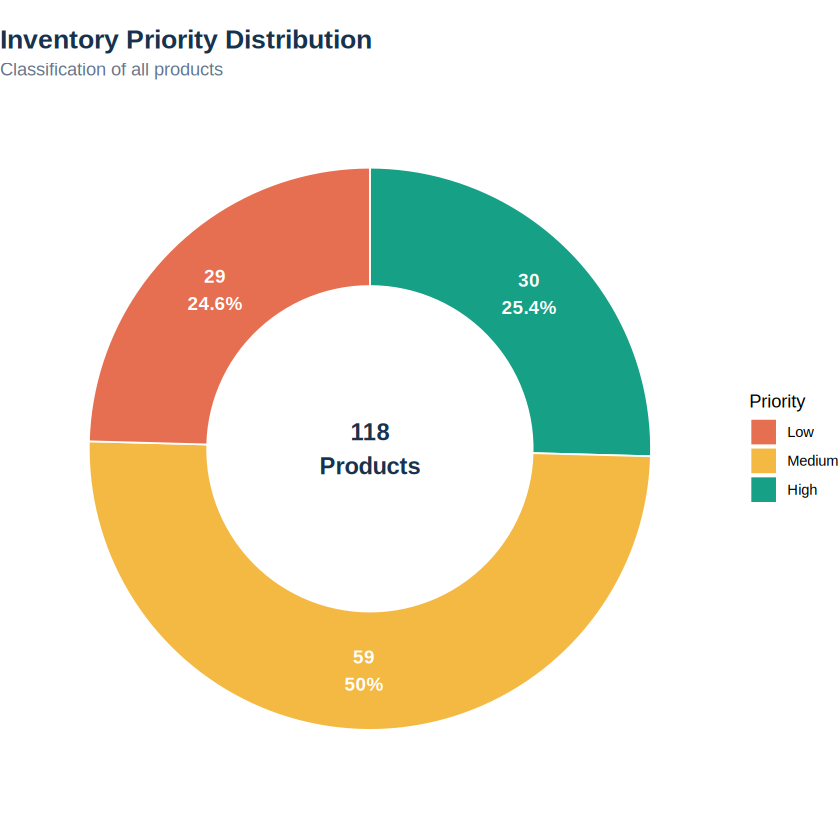

In [23]:
p1 <- ggplot(
  priority_summary,
  aes(
    x = 2,
    y = count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.8, color = "white") +
  coord_polar(theta = "y") +
  xlim(0.5, 2.5) +
  scale_fill_manual(values = priority_colors) +
  geom_text(
    aes(label = paste0(count, "\n",
                       round(count / sum(count) * 100, 1), "%")),
    position = position_stack(vjust = 0.5),
    color = "white",
    fontface = "bold",
    size = 4
  ) +
  annotate(
    "text", x = 0.5, y = 0,
    label = paste0(sum(priority_summary$count),
                   "\nProducts"),
    fontface = "bold", size = 5,
    color = "#17324D"
  ) +
  labs(
    title = "Inventory Priority Distribution",
    subtitle = "Classification of all products",
    fill = "Priority"
  ) +
  theme_void() +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(color = "#64748B")
  )

print(p1)

### Chart 2: Product Count by Priority (Bar Chart)

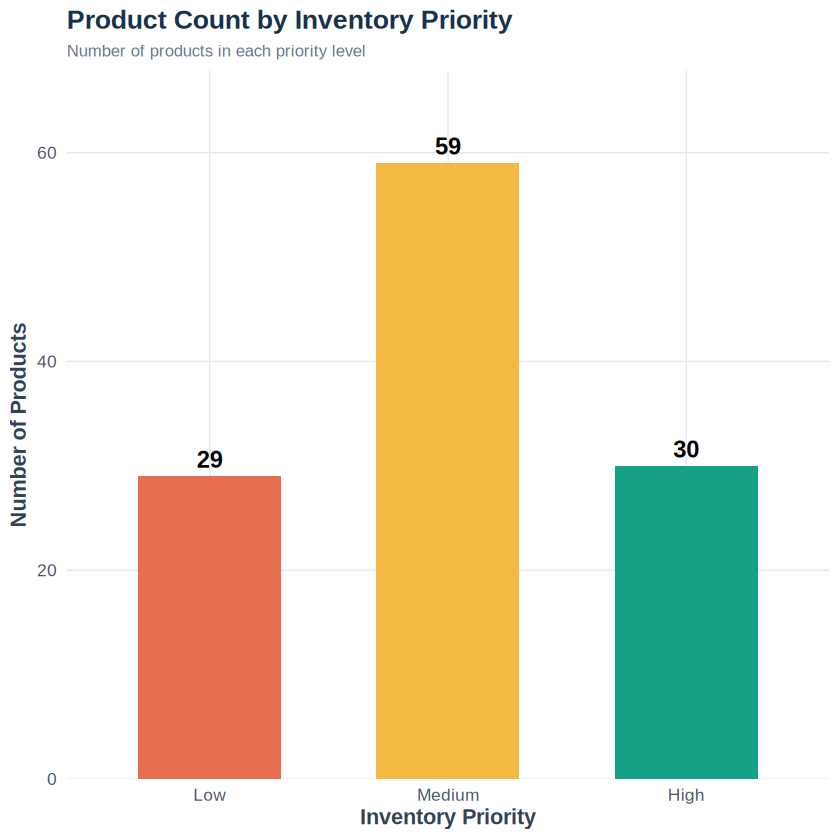

In [24]:
p2 <- ggplot(
  priority_summary,
  aes(
    x = inventory_priority,
    y = count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.6, show.legend = FALSE) +
  geom_text(
    aes(label = count),
    vjust = -0.5,
    fontface = "bold",
    size = 5
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Product Count by Inventory Priority",
    subtitle = "Number of products in each priority level",
    x = "Inventory Priority",
    y = "Number of Products"
  ) +
  my_theme

print(p2)

### Chart 3: Top 15 Categories by Product Count (Horizontal Bar Chart)

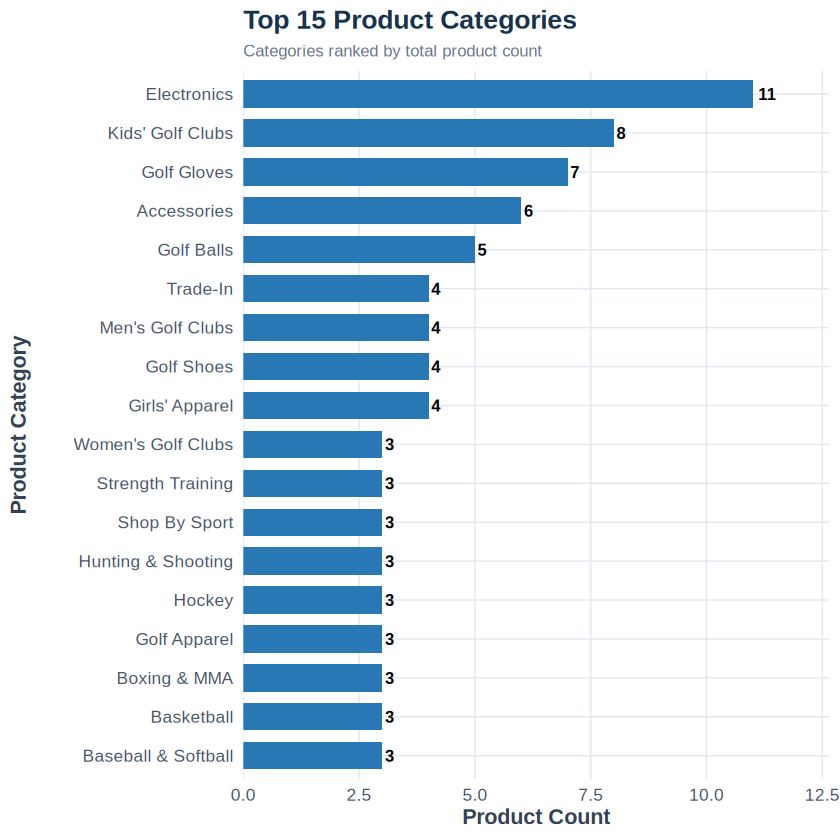

In [25]:
top_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total_products = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total_products, n = 15) %>%
  arrange(total_products)

p3 <- ggplot(
  top_categories,
  aes(
    x = reorder(category_name, total_products),
    y = total_products
  )
) +
  geom_col(
    fill = "#2878B5",
    width = 0.7
  ) +
  geom_text(
    aes(label = total_products),
    hjust = -0.3,
    fontface = "bold",
    size = 3.5
  ) +
  coord_flip() +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Top 15 Product Categories",
    subtitle = "Categories ranked by total product count",
    x = "Product Category",
    y = "Product Count"
  ) +
  my_theme

print(p3)

### Chart 4: Product Quantity by Priority (Bar Chart)

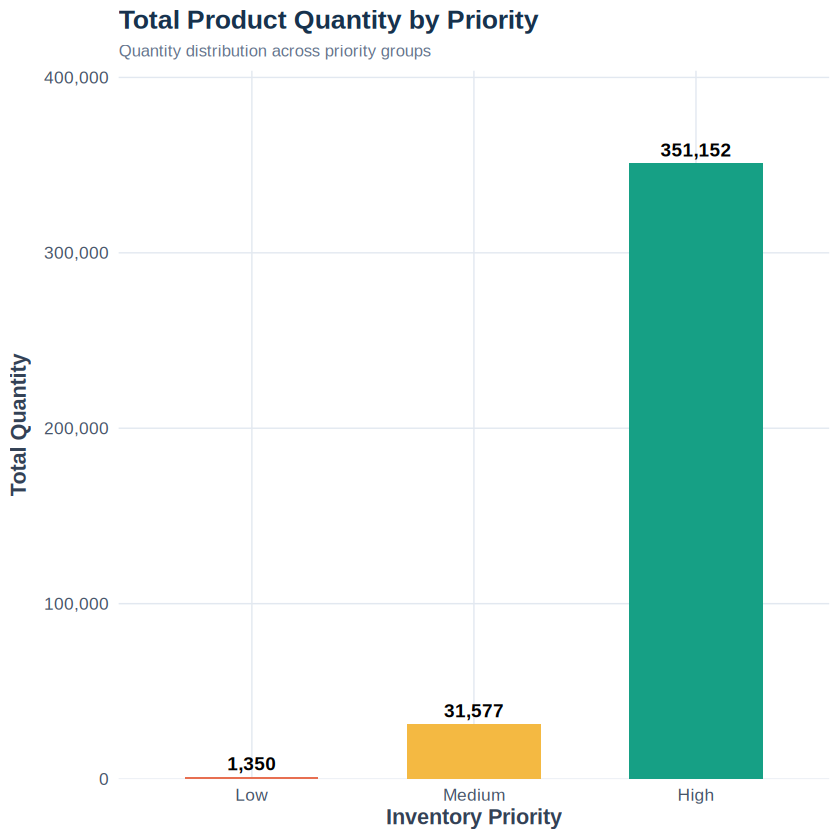

In [26]:
quantity_priority <- inventory %>%
  group_by(inventory_priority) %>%
  summarise(
    total_quantity = sum(total_quantity),
    .groups = "drop"
  )

p4 <- ggplot(
  quantity_priority,
  aes(
    x = inventory_priority,
    y = total_quantity,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.6, show.legend = FALSE) +
  geom_text(
    aes(label = comma(total_quantity)),
    vjust = -0.5,
    fontface = "bold",
    size = 4
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    labels = comma,
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Total Product Quantity by Priority",
    subtitle = "Quantity distribution across priority groups",
    x = "Inventory Priority",
    y = "Total Quantity"
  ) +
  my_theme

print(p4)

### Chart 5: Category-wise Priority Distribution (100% Stacked Bar Chart)

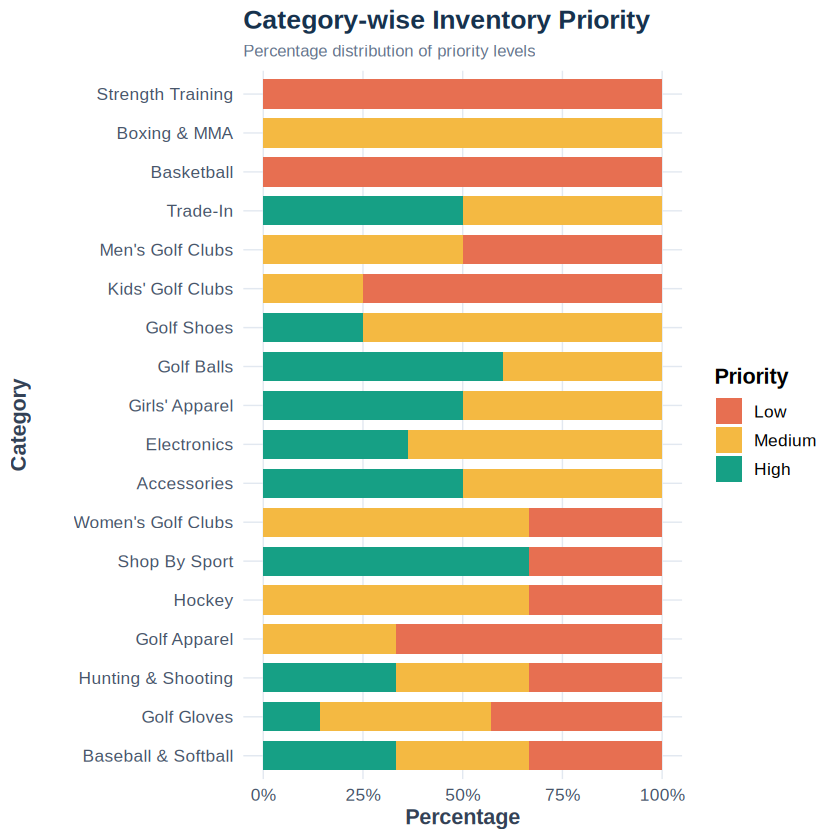

In [27]:
top_12_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total, n = 12) %>%
  pull(category_name)

category_percentage <- category_data %>%
  filter(category_name %in% top_12_categories) %>%
  group_by(category_name) %>%
  mutate(
    percentage = product_count / sum(product_count) * 100
  ) %>%
  ungroup()

p5 <- ggplot(
  category_percentage,
  aes(
    x = reorder(category_name, percentage),
    y = percentage,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.75) +
  coord_flip() +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    labels = label_percent(scale = 1)
  ) +
  labs(
    title = "Category-wise Inventory Priority",
    subtitle = "Percentage distribution of priority levels",
    x = "Category",
    y = "Percentage",
    fill = "Priority"
  ) +
  my_theme

print(p5)

### Chart 6: Top Categories by Priority (Stacked Bar Chart)

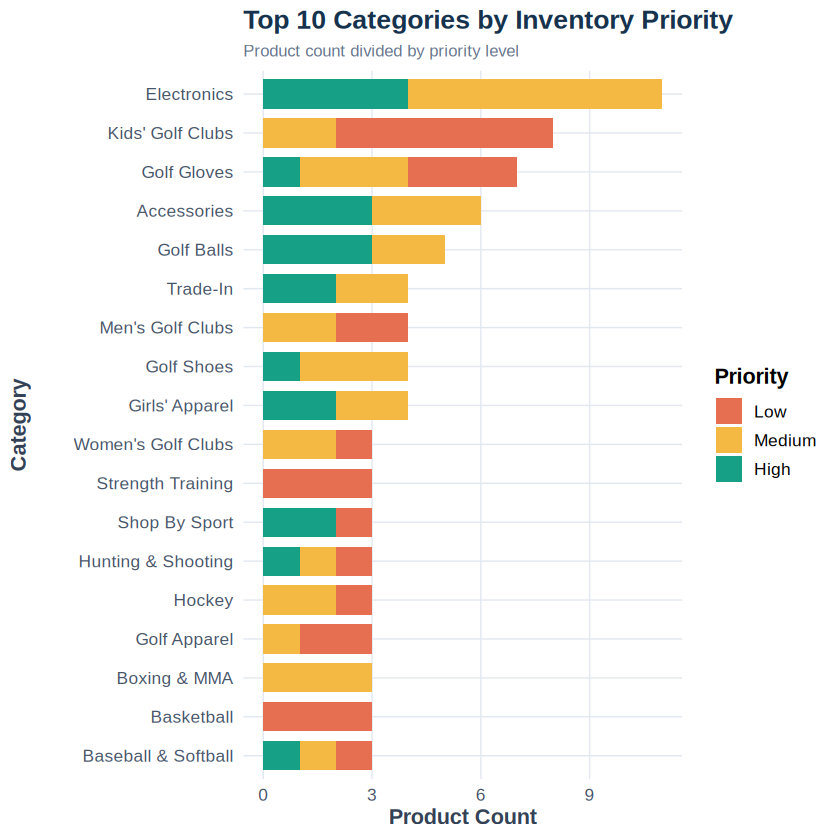

In [28]:
top_10_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total, n = 10) %>%
  pull(category_name)

p6 <- ggplot(
  filter(category_data,
         category_name %in% top_10_categories),
  aes(
    x = reorder(category_name, product_count,
                FUN = sum),
    y = product_count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.75) +
  coord_flip() +
  scale_fill_manual(values = priority_colors) +
  labs(
    title = "Top 10 Categories by Inventory Priority",
    subtitle = "Product count divided by priority level",
    x = "Category",
    y = "Product Count",
    fill = "Priority"
  ) +
  my_theme

print(p6)

### Chart 7: Category vs Priority Heatmap

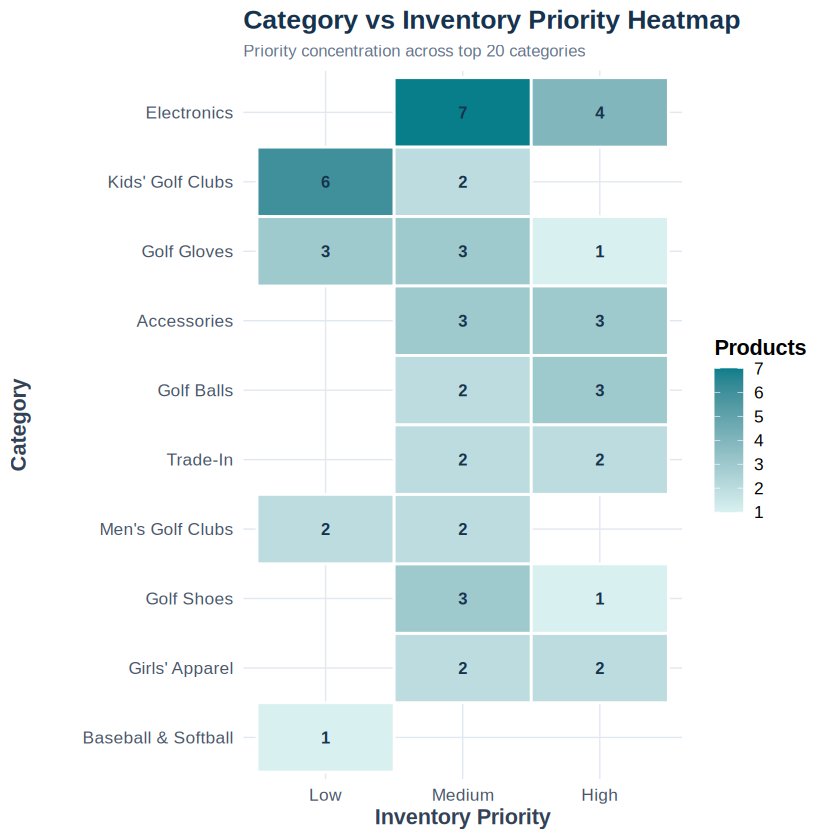

In [29]:
heatmap_data <- category_data %>%
  group_by(category_name) %>%
  mutate(total = sum(product_count)) %>%
  ungroup() %>%
  slice_max(total, n = 20, with_ties = FALSE)

p7 <- ggplot(
  heatmap_data,
  aes(
    x = inventory_priority,
    y = reorder(category_name, total),
    fill = product_count
  )
) +
  geom_tile(
    color = "white",
    linewidth = 0.8
  ) +
  geom_text(
    aes(label = product_count),
    color = "#17324D",
    fontface = "bold",
    size = 3.5
  ) +
  scale_fill_gradient(
    low = "#D9F0F0",
    high = "#087E8B"
  ) +
  labs(
    title = "Category vs Inventory Priority Heatmap",
    subtitle = "Priority concentration across top 20 categories",
    x = "Inventory Priority",
    y = "Category",
    fill = "Products"
  ) +
  my_theme

print(p7)

### Chart 8: Total Sales vs Quantity Sold (Scatter Plot)

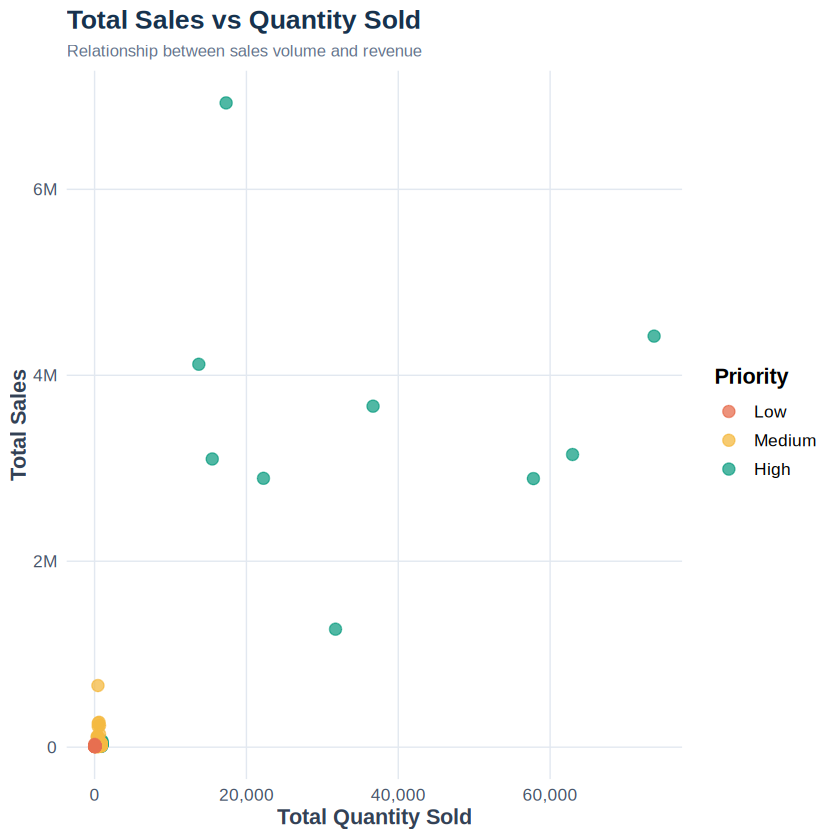

In [30]:
p8 <- ggplot(
  inventory,
  aes(
    x = total_quantity,
    y = total_sales,
    color = inventory_priority
  )
) +
  geom_point(
    size = 3,
    alpha = 0.75
  ) +
  scale_color_manual(values = priority_colors) +
  scale_x_continuous(labels = comma) +
  scale_y_continuous(labels = label_number(
    scale_cut = cut_short_scale()
  )) +
  labs(
    title = "Total Sales vs Quantity Sold",
    subtitle = "Relationship between sales volume and revenue",
    x = "Total Quantity Sold",
    y = "Total Sales",
    color = "Priority"
  ) +
  my_theme

print(p8)

### Chart 9: Average Sales vs Quantity Sold (Scatter Plot)

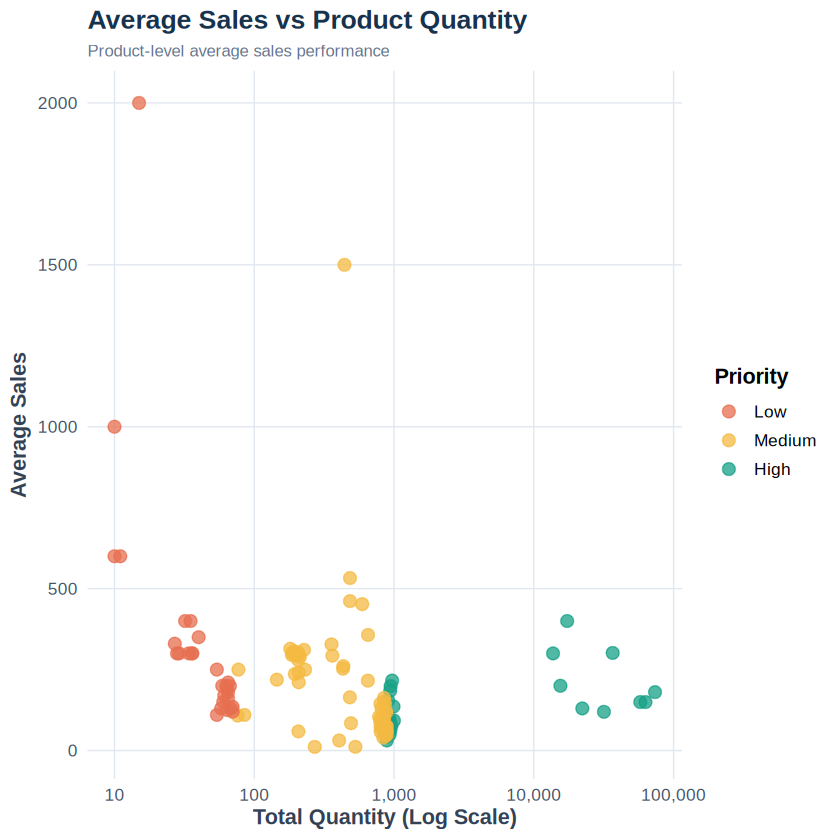

In [31]:
p9 <- ggplot(
  inventory,
  aes(
    x = total_quantity,
    y = average_sales,
    color = inventory_priority
  )
) +
  geom_point(
    size = 3.2,
    alpha = 0.75
  ) +
  scale_x_log10(labels = comma) +
  scale_color_manual(values = priority_colors) +
  labs(
    title = "Average Sales vs Product Quantity",
    subtitle = "Product-level average sales performance",
    x = "Total Quantity (Log Scale)",
    y = "Average Sales",
    color = "Priority"
  ) +
  my_theme

print(p9)

### Chart 10: Distribution of Product Sales (Histogram)

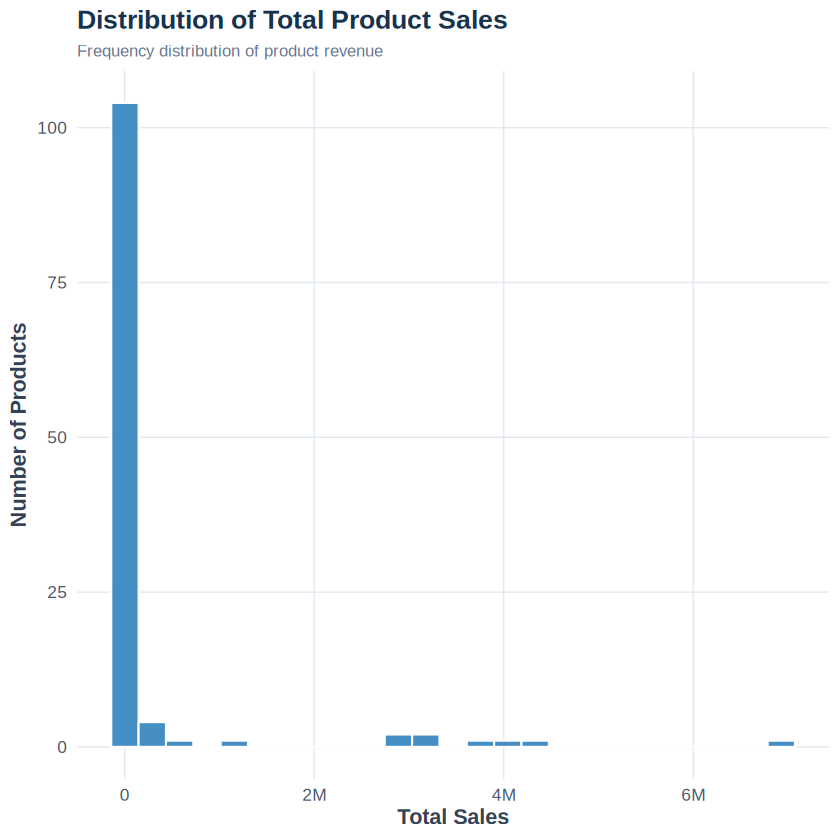

In [32]:
p10 <- ggplot(
  inventory,
  aes(x = total_sales)
) +
  geom_histogram(
    bins = 25,
    fill = "#3182BD",
    color = "white",
    alpha = 0.9
  ) +
  scale_x_continuous(
    labels = label_number(
      scale_cut = cut_short_scale()
    )
  ) +
  labs(
    title = "Distribution of Total Product Sales",
    subtitle = "Frequency distribution of product revenue",
    x = "Total Sales",
    y = "Number of Products"
  ) +
  my_theme

print(p10)

### Chart 11: Sales Distribution by Priority (Boxplot)

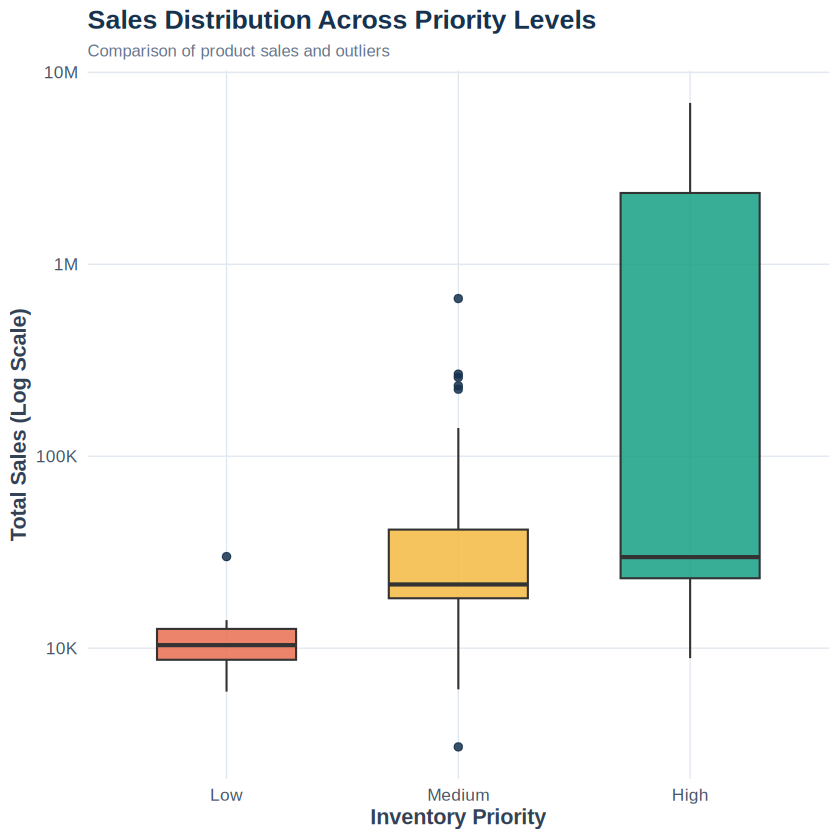

In [33]:
p11 <- ggplot(
  inventory,
  aes(
    x = inventory_priority,
    y = total_sales,
    fill = inventory_priority
  )
) +
  geom_boxplot(
    width = 0.6,
    alpha = 0.85,
    outlier.color = "#17324D",
    outlier.size = 2
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_log10(
    labels = label_number(
      scale_cut = cut_short_scale()
    )
  ) +
  labs(
    title = "Sales Distribution Across Priority Levels",
    subtitle = "Comparison of product sales and outliers",
    x = "Inventory Priority",
    y = "Total Sales (Log Scale)"
  ) +
  my_theme +
  theme(legend.position = "none")

print(p11)

### Chart 12: Product Sales Contribution (Treemap)

Warning message in geom_treemap(color = "white", linewidth = 2):
“Ignoring unknown parameters: `linewidth`”


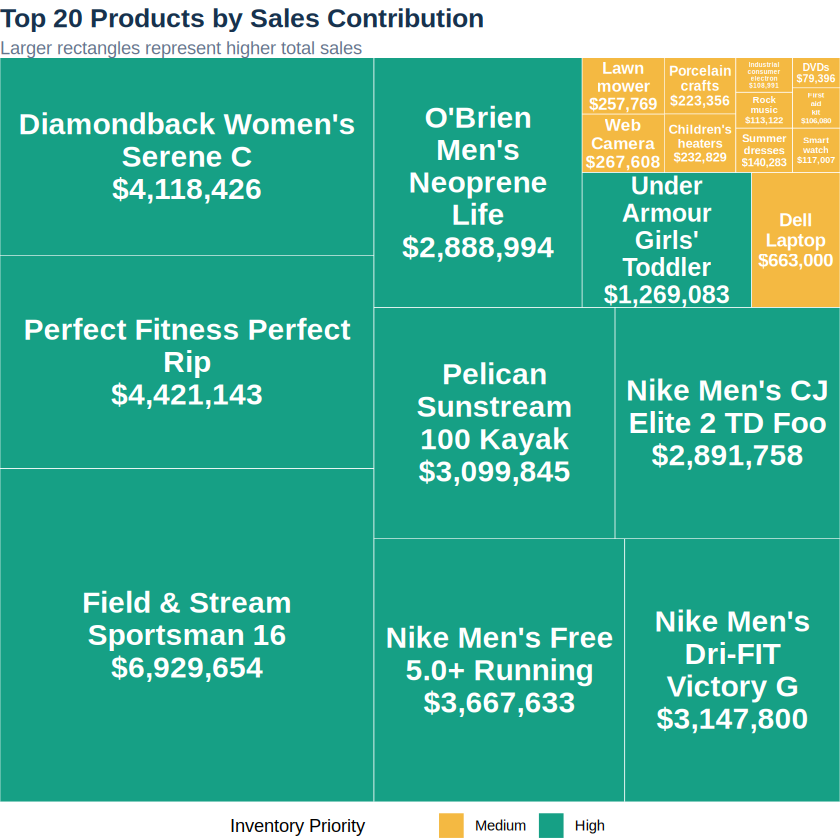

In [34]:
treemap_data <- inventory %>%
  slice_max(total_sales, n = 20) %>%
  mutate(
    short_name = substr(product_name, 1, 28)
  )

p12 <- ggplot(
  treemap_data,
  aes(
    area = total_sales,
    fill = inventory_priority,
    label = paste0(
      short_name,
      "\n",
      dollar(total_sales, accuracy = 1)
    )
  )
) +
  geom_treemap(
    color = "white",
    linewidth = 2
  ) +
  geom_treemap_text(
    place = "centre",
    grow = FALSE,
    reflow = TRUE,
    colour = "white",
    fontface = "bold",
    min.size = 3
  ) +
  scale_fill_manual(values = priority_colors) +
  labs(
    title = "Top 20 Products by Sales Contribution",
    subtitle = "Larger rectangles represent higher total sales",
    fill = "Inventory Priority"
  ) +
  theme_void() +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(color = "#64748B"),
    legend.position = "bottom"
  )

print(p12)

All datasets loaded successfully!

Priority by Category: 72 records
Priority Summary: 3 records
Inventory Priority: 118 records


,product_card_id,product_name,total_quantity,total_sales,average_sales,inventory_priority
,<int>,<chr>,<int>,<dbl>,<dbl>,<chr>
1,365,Perfect Fitness Perfect Rip Deck,73698,4421143,180.3444,High
2,502,Nike Men's Dri-FIT Victory Golf Polo,62956,3147800,149.6458,High
3,1014,O'Brien Men's Neoprene Life Vest,57803,2888994,149.7043,High
4,191,Nike Men's Free 5.0+ Running Shoe,36680,3667633,301.3915,High
5,627,Under Armour Girls' Toddler Spine Surge Runni,31735,1269083,119.5331,High
6,403,Nike Men's CJ Elite 2 TD Football Cleat,22246,2891758,129.9900,High


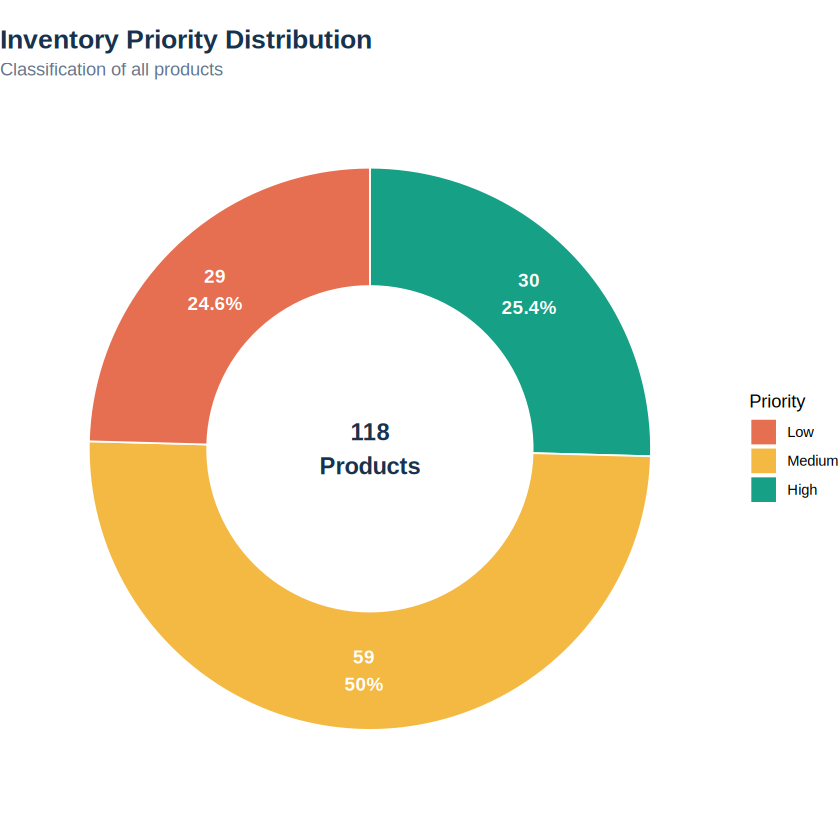

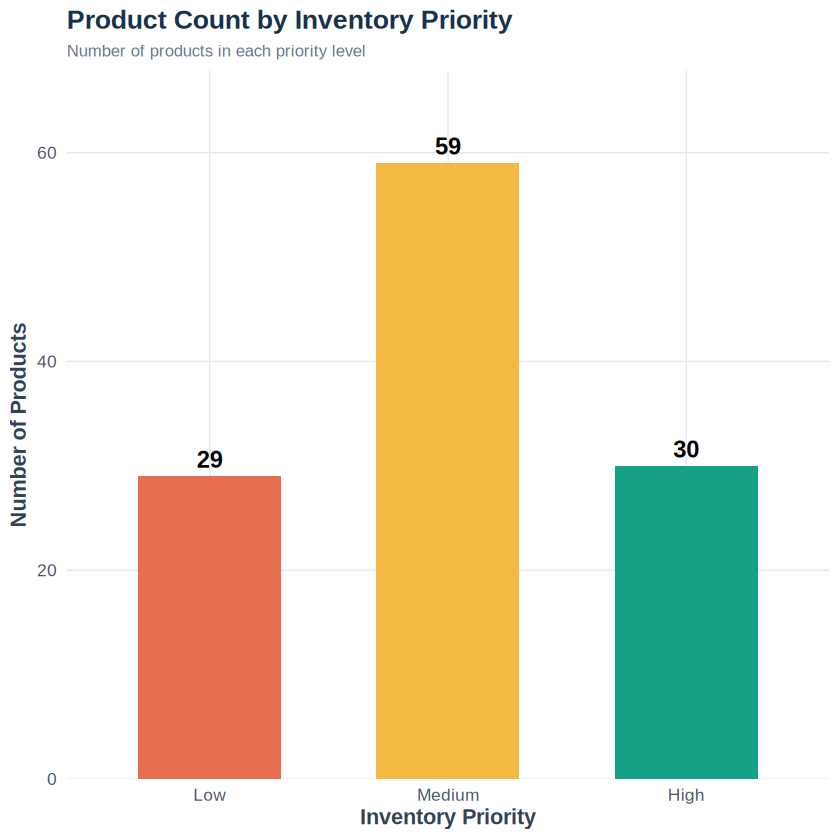

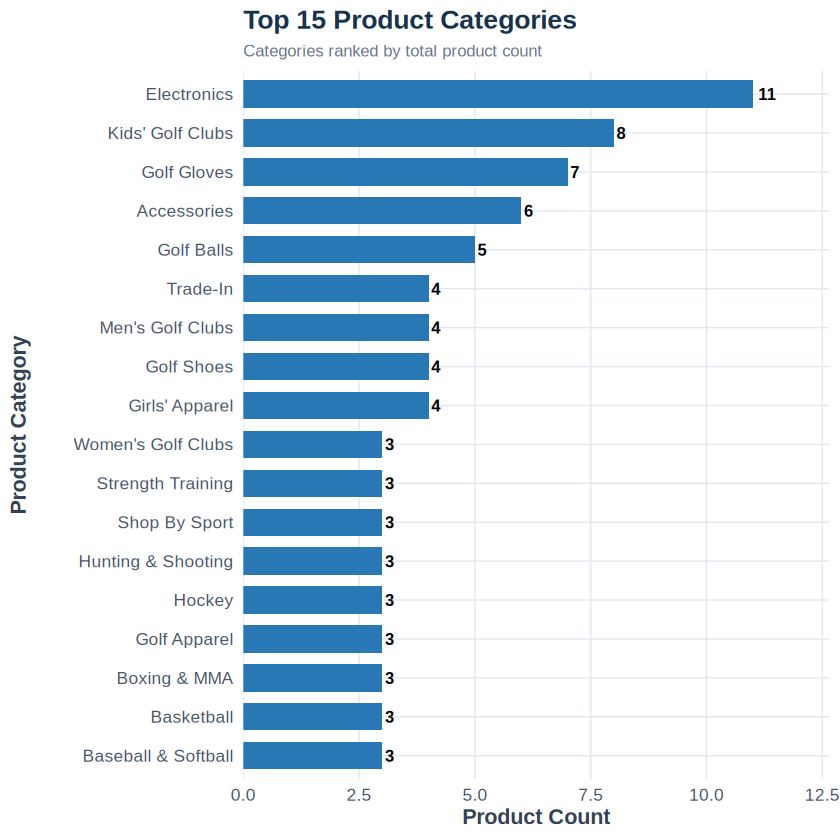

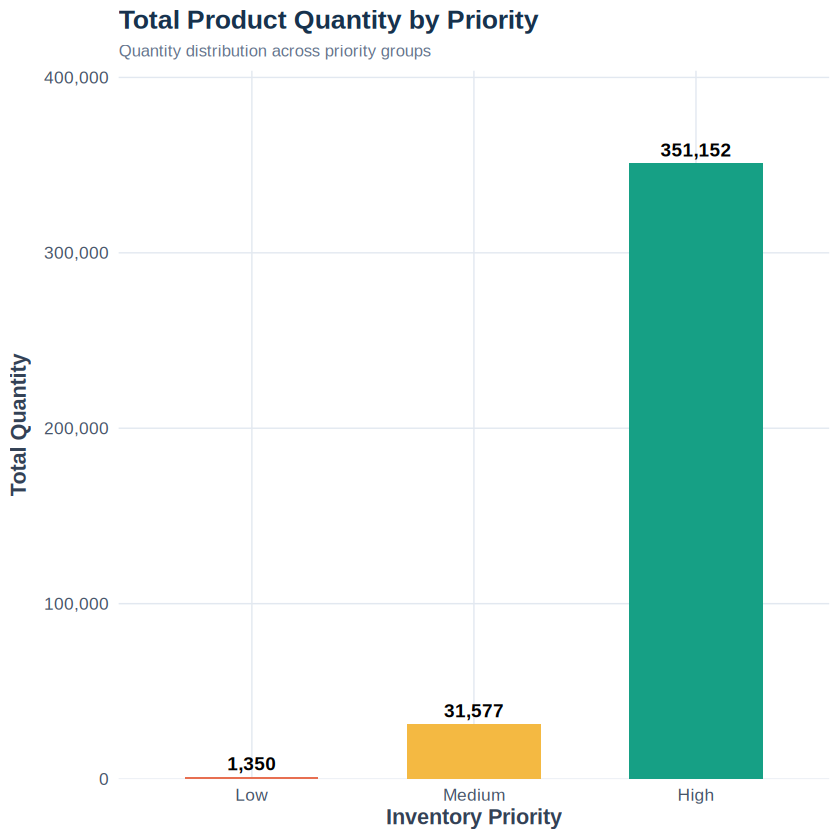

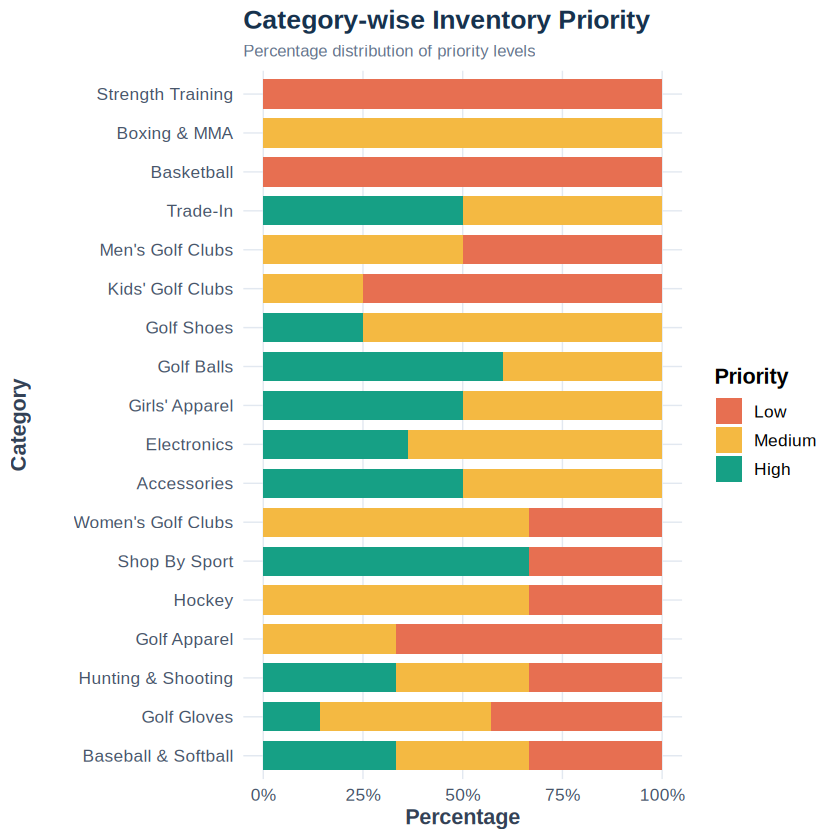

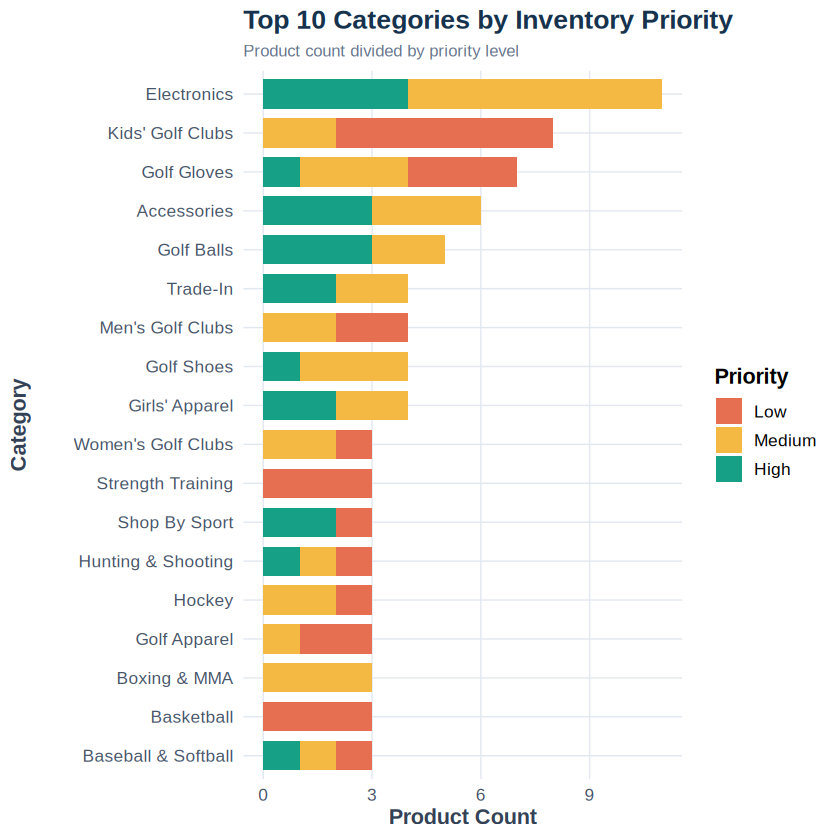

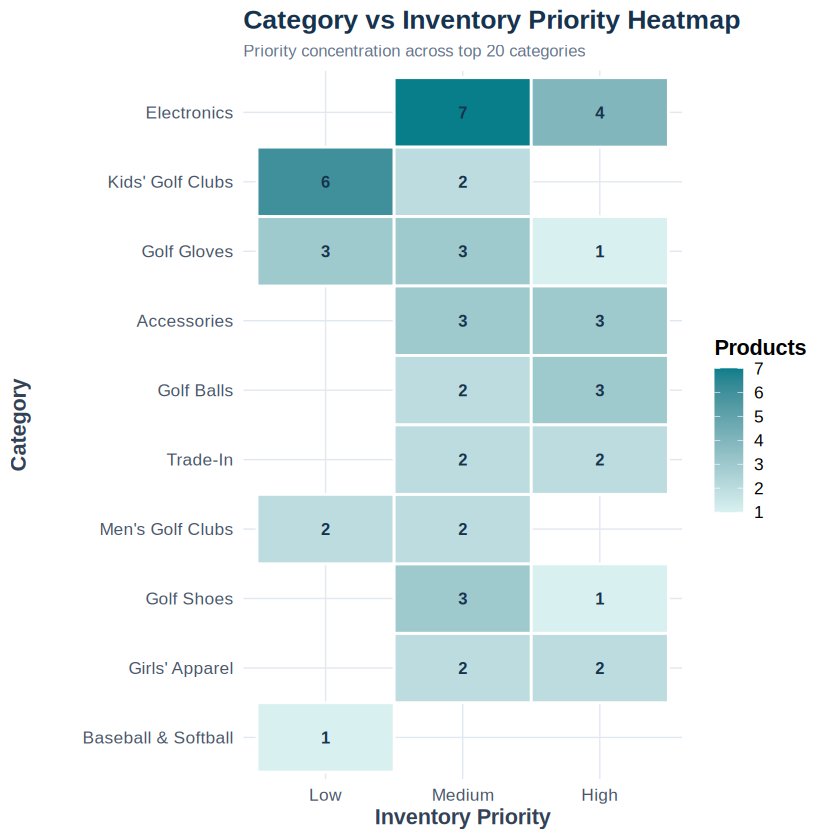

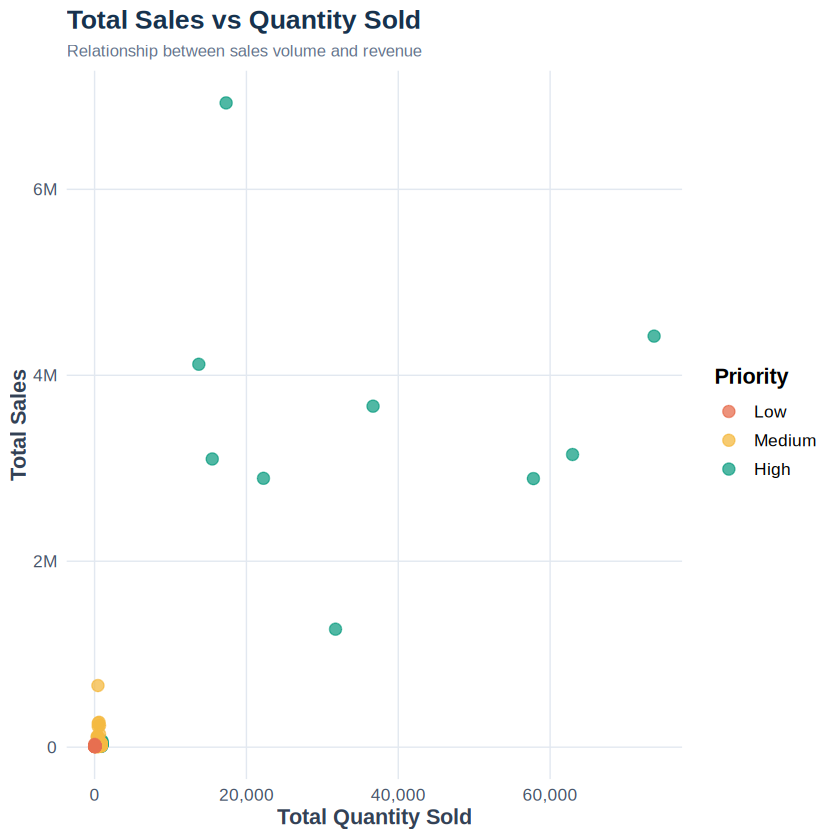

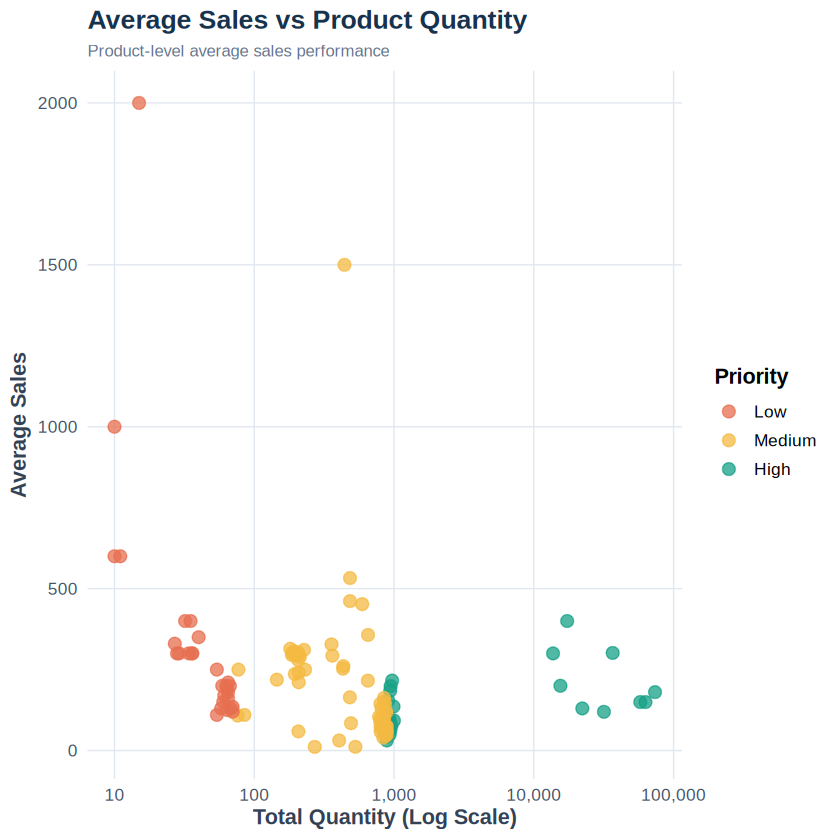

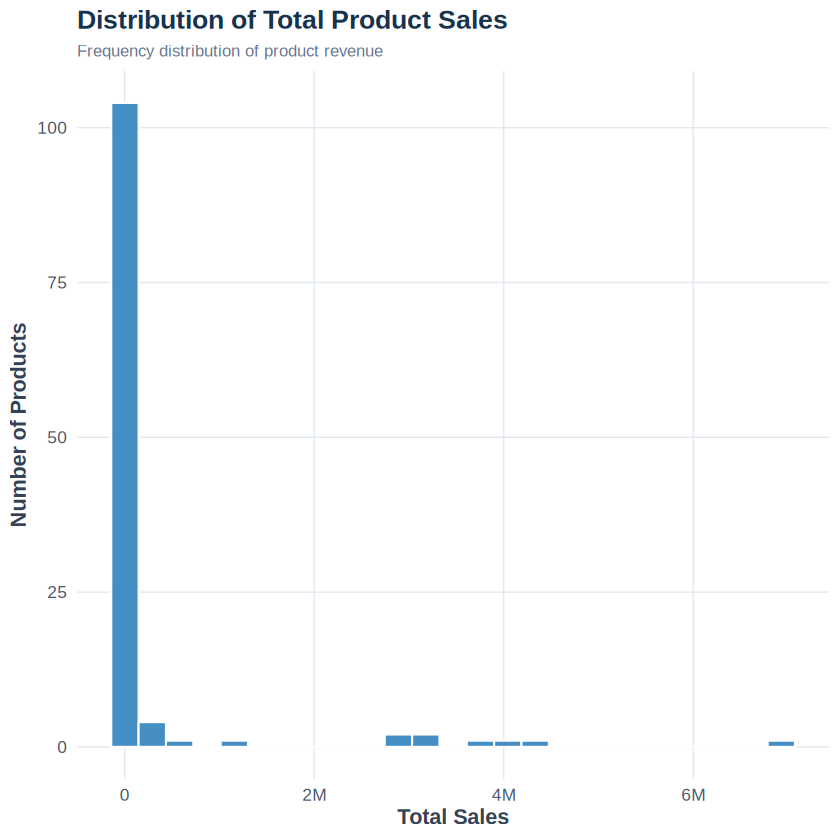

Warning message in geom_treemap(color = "white", linewidth = 2):
“Ignoring unknown parameters: `linewidth`”


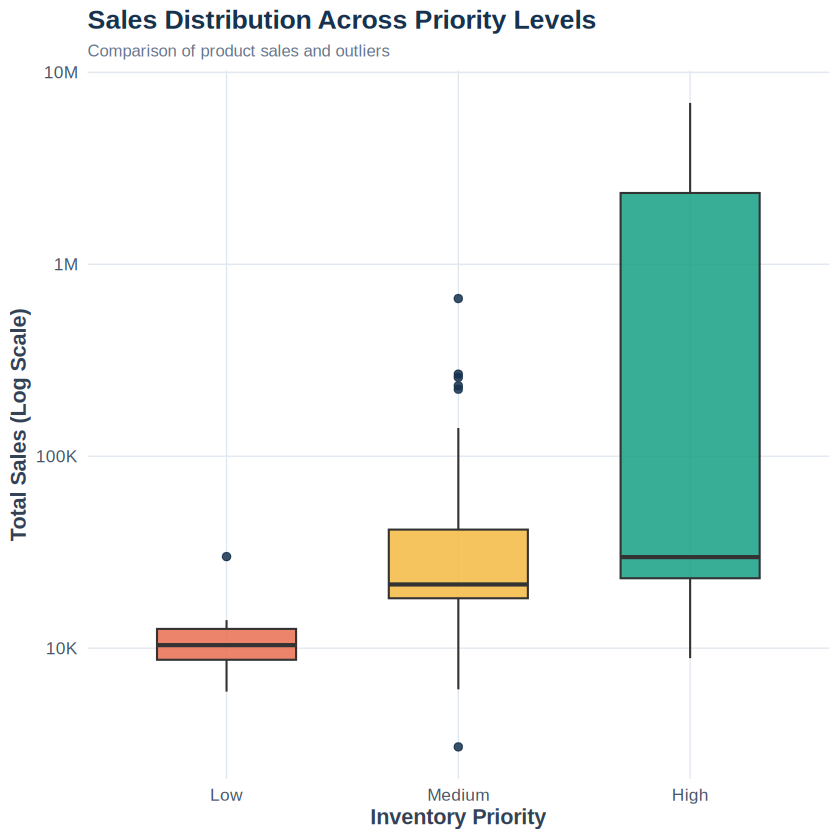


All 12 visualizations generated successfully!


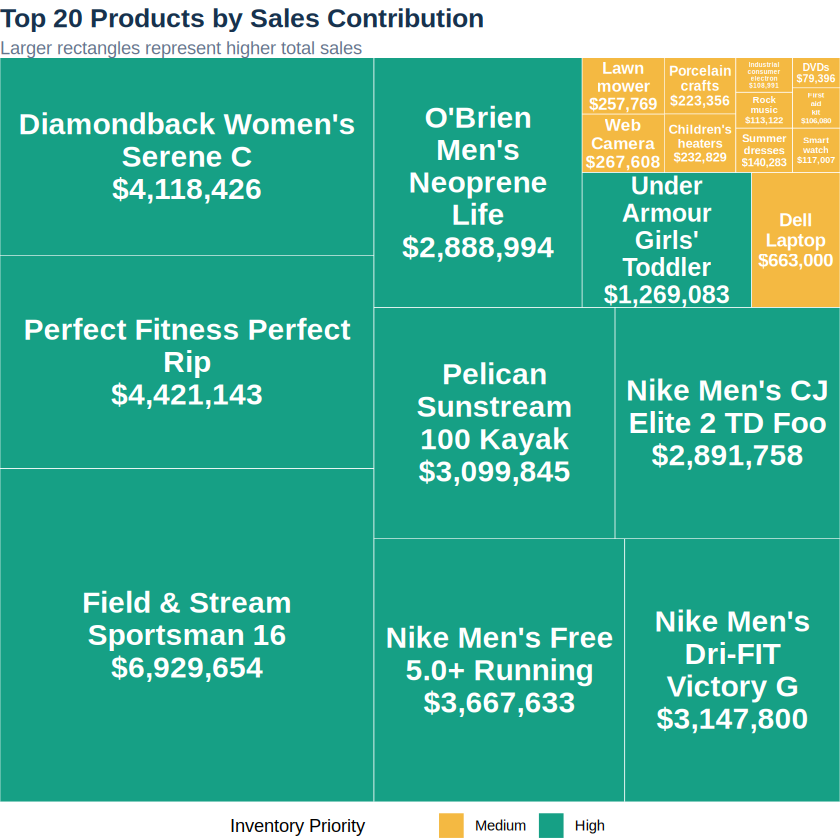

In [2]:
# 1. Install and load packages
packages <- c("ggplot2", "dplyr", "tidyr", "scales", "treemapify")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}

library(ggplot2)
library(dplyr)
library(tidyr)
library(scales)
library(treemapify)

# ============================================================
# 2. LOAD DATASETS - GOOGLE COLAB
# ============================================================

priority_category <- read.csv(
  "/content/priority_by_category.csv",
  stringsAsFactors = FALSE
)

priority_summary <- read.csv(
  "/content/priority_summary.csv",
  stringsAsFactors = FALSE
)

inventory <- read.csv(
  "/content/inventory_priority.csv",
  stringsAsFactors = FALSE
)

# Verify successful loading
cat("All datasets loaded successfully!\n\n")

cat("Priority by Category:", nrow(priority_category), "records\n")
cat("Priority Summary:", nrow(priority_summary), "records\n")
cat("Inventory Priority:", nrow(inventory), "records\n")

# Display first five records
head(inventory)

# ============================================================
# 3. DATA PREPARATION
# ============================================================

priority_colors <- c(
  "High" = "#16A085",
  "Medium" = "#F4B942",
  "Low" = "#E76F51"
)

priority_order <- c("Low", "Medium", "High")

priority_category$inventory_priority <- factor(
  priority_category$inventory_priority,
  levels = priority_order
)

priority_summary$inventory_priority <- factor(
  priority_summary$inventory_priority,
  levels = priority_order
)

inventory$inventory_priority <- factor(
  inventory$inventory_priority,
  levels = priority_order
)

# Aggregate repeated category-priority combinations
category_data <- priority_category %>%
  group_by(category_name, inventory_priority) %>%
  summarise(
    product_count = sum(product_count, na.rm = TRUE),
    .groups = "drop"
  )

# Clean inventory data
inventory <- inventory %>%
  filter(
    !is.na(total_sales),
    !is.na(total_quantity),
    !is.na(average_sales),
    total_sales >= 0,
    total_quantity >= 0
  )

# Common professional theme
my_theme <- theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(
      color = "#64748B", size = 10
    ),
    axis.title = element_text(
      face = "bold", color = "#334155"
    ),
    axis.text = element_text(color = "#475569"),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(
      color = "#E2E8F0", linewidth = 0.4
    ),
    legend.title = element_text(face = "bold"),
    plot.background = element_rect(
      fill = "white", color = NA
    )
  )

# ============================================================
# CHART 1: INVENTORY PRIORITY DISTRIBUTION
# Chart Type: Donut Chart
# Dataset: priority_summary
# ============================================================

p1 <- ggplot(
  priority_summary,
  aes(
    x = 2,
    y = count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.8, color = "white") +
  coord_polar(theta = "y") +
  xlim(0.5, 2.5) +
  scale_fill_manual(values = priority_colors) +
  geom_text(
    aes(label = paste0(count, "\n",
                       round(count / sum(count) * 100, 1), "%")),
    position = position_stack(vjust = 0.5),
    color = "white",
    fontface = "bold",
    size = 4
  ) +
  annotate(
    "text", x = 0.5, y = 0,
    label = paste0(sum(priority_summary$count),
                   "\nProducts"),
    fontface = "bold", size = 5,
    color = "#17324D"
  ) +
  labs(
    title = "Inventory Priority Distribution",
    subtitle = "Classification of all products",
    fill = "Priority"
  ) +
  theme_void() +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(color = "#64748B")
  )

print(p1)


# ============================================================
# CHART 2: PRODUCT COUNT BY PRIORITY
# Chart Type: Bar Chart
# Dataset: priority_summary
# ============================================================

p2 <- ggplot(
  priority_summary,
  aes(
    x = inventory_priority,
    y = count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.6, show.legend = FALSE) +
  geom_text(
    aes(label = count),
    vjust = -0.5,
    fontface = "bold",
    size = 5
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Product Count by Inventory Priority",
    subtitle = "Number of products in each priority level",
    x = "Inventory Priority",
    y = "Number of Products"
  ) +
  my_theme

print(p2)


# ============================================================
# CHART 3: TOP 15 CATEGORIES BY PRODUCT COUNT
# Chart Type: Horizontal Bar Chart
# Dataset: priority_by_category
# ============================================================

top_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total_products = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total_products, n = 15) %>%
  arrange(total_products)

p3 <- ggplot(
  top_categories,
  aes(
    x = reorder(category_name, total_products),
    y = total_products
  )
) +
  geom_col(
    fill = "#2878B5",
    width = 0.7
  ) +
  geom_text(
    aes(label = total_products),
    hjust = -0.3,
    fontface = "bold",
    size = 3.5
  ) +
  coord_flip() +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Top 15 Product Categories",
    subtitle = "Categories ranked by total product count",
    x = "Product Category",
    y = "Product Count"
  ) +
  my_theme

print(p3)


# ============================================================
# CHART 4: PRODUCT QUANTITY BY PRIORITY
# Chart Type: Bar Chart
# Dataset: inventory_priority
# ============================================================

quantity_priority <- inventory %>%
  group_by(inventory_priority) %>%
  summarise(
    total_quantity = sum(total_quantity),
    .groups = "drop"
  )

p4 <- ggplot(
  quantity_priority,
  aes(
    x = inventory_priority,
    y = total_quantity,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.6, show.legend = FALSE) +
  geom_text(
    aes(label = comma(total_quantity)),
    vjust = -0.5,
    fontface = "bold",
    size = 4
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    labels = comma,
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Total Product Quantity by Priority",
    subtitle = "Quantity distribution across priority groups",
    x = "Inventory Priority",
    y = "Total Quantity"
  ) +
  my_theme

print(p4)


# ============================================================
# CHART 5: CATEGORY-WISE PRIORITY DISTRIBUTION
# Chart Type: 100% Stacked Bar Chart
# Dataset: priority_by_category
# ============================================================

top_12_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total, n = 12) %>%
  pull(category_name)

category_percentage <- category_data %>%
  filter(category_name %in% top_12_categories) %>%
  group_by(category_name) %>%
  mutate(
    percentage = product_count / sum(product_count) * 100
  ) %>%
  ungroup()

p5 <- ggplot(
  category_percentage,
  aes(
    x = reorder(category_name, percentage),
    y = percentage,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.75) +
  coord_flip() +
  scale_fill_manual(values = priority_colors) +
  scale_y_continuous(
    labels = label_percent(scale = 1)
  ) +
  labs(
    title = "Category-wise Inventory Priority",
    subtitle = "Percentage distribution of priority levels",
    x = "Category",
    y = "Percentage",
    fill = "Priority"
  ) +
  my_theme

print(p5)


# ============================================================
# CHART 6: TOP CATEGORIES BY PRIORITY
# Chart Type: Stacked Bar Chart
# Dataset: priority_by_category
# ============================================================

top_10_categories <- category_data %>%
  group_by(category_name) %>%
  summarise(
    total = sum(product_count),
    .groups = "drop"
  ) %>%
  slice_max(total, n = 10) %>%
  pull(category_name)

p6 <- ggplot(
  filter(category_data,
         category_name %in% top_10_categories),
  aes(
    x = reorder(category_name, product_count,
                FUN = sum),
    y = product_count,
    fill = inventory_priority
  )
) +
  geom_col(width = 0.75) +
  coord_flip() +
  scale_fill_manual(values = priority_colors) +
  labs(
    title = "Top 10 Categories by Inventory Priority",
    subtitle = "Product count divided by priority level",
    x = "Category",
    y = "Product Count",
    fill = "Priority"
  ) +
  my_theme

print(p6)


# ============================================================
# CHART 7: CATEGORY VS PRIORITY HEATMAP
# Chart Type: Heatmap
# Dataset: priority_by_category
# ============================================================

heatmap_data <- category_data %>%
  group_by(category_name) %>%
  mutate(total = sum(product_count)) %>%
  ungroup() %>%
  slice_max(total, n = 20, with_ties = FALSE)

p7 <- ggplot(
  heatmap_data,
  aes(
    x = inventory_priority,
    y = reorder(category_name, total),
    fill = product_count
  )
) +
  geom_tile(
    color = "white",
    linewidth = 0.8
  ) +
  geom_text(
    aes(label = product_count),
    color = "#17324D",
    fontface = "bold",
    size = 3.5
  ) +
  scale_fill_gradient(
    low = "#D9F0F0",
    high = "#087E8B"
  ) +
  labs(
    title = "Category vs Inventory Priority Heatmap",
    subtitle = "Priority concentration across top 20 categories",
    x = "Inventory Priority",
    y = "Category",
    fill = "Products"
  ) +
  my_theme

print(p7)


# ============================================================
# CHART 8: TOTAL SALES VS QUANTITY SOLD
# Chart Type: Scatter Plot
# Dataset: inventory_priority
# ============================================================

p8 <- ggplot(
  inventory,
  aes(
    x = total_quantity,
    y = total_sales,
    color = inventory_priority
  )
) +
  geom_point(
    size = 3,
    alpha = 0.75
  ) +
  scale_color_manual(values = priority_colors) +
  scale_x_continuous(labels = comma) +
  scale_y_continuous(labels = label_number(
    scale_cut = cut_short_scale()
  )) +
  labs(
    title = "Total Sales vs Quantity Sold",
    subtitle = "Relationship between sales volume and revenue",
    x = "Total Quantity Sold",
    y = "Total Sales",
    color = "Priority"
  ) +
  my_theme

print(p8)


# ============================================================
# CHART 9: AVERAGE SALES VS QUANTITY SOLD
# Chart Type: Scatter Plot
# Dataset: inventory_priority
# ============================================================

p9 <- ggplot(
  inventory,
  aes(
    x = total_quantity,
    y = average_sales,
    color = inventory_priority
  )
) +
  geom_point(
    size = 3.2,
    alpha = 0.75
  ) +
  scale_x_log10(labels = comma) +
  scale_color_manual(values = priority_colors) +
  labs(
    title = "Average Sales vs Product Quantity",
    subtitle = "Product-level average sales performance",
    x = "Total Quantity (Log Scale)",
    y = "Average Sales",
    color = "Priority"
  ) +
  my_theme

print(p9)


# ============================================================
# CHART 10: DISTRIBUTION OF PRODUCT SALES
# Chart Type: Histogram
# Dataset: inventory_priority
# ============================================================

p10 <- ggplot(
  inventory,
  aes(x = total_sales)
) +
  geom_histogram(
    bins = 25,
    fill = "#3182BD",
    color = "white",
    alpha = 0.9
  ) +
  scale_x_continuous(
    labels = label_number(
      scale_cut = cut_short_scale()
    )
  ) +
  labs(
    title = "Distribution of Total Product Sales",
    subtitle = "Frequency distribution of product revenue",
    x = "Total Sales",
    y = "Number of Products"
  ) +
  my_theme

print(p10)


# ============================================================
# CHART 11: SALES DISTRIBUTION BY PRIORITY
# Chart Type: Boxplot
# Dataset: inventory_priority
# ============================================================

p11 <- ggplot(
  inventory,
  aes(
    x = inventory_priority,
    y = total_sales,
    fill = inventory_priority
  )
) +
  geom_boxplot(
    width = 0.6,
    alpha = 0.85,
    outlier.color = "#17324D",
    outlier.size = 2
  ) +
  scale_fill_manual(values = priority_colors) +
  scale_y_log10(
    labels = label_number(
      scale_cut = cut_short_scale()
    )
  ) +
  labs(
    title = "Sales Distribution Across Priority Levels",
    subtitle = "Comparison of product sales and outliers",
    x = "Inventory Priority",
    y = "Total Sales (Log Scale)"
  ) +
  my_theme +
  theme(legend.position = "none")

print(p11)


# ============================================================
# CHART 12: PRODUCT SALES CONTRIBUTION
# Chart Type: Treemap
# Dataset: inventory_priority
# ============================================================

treemap_data <- inventory %>%
  slice_max(total_sales, n = 20) %>%
  mutate(
    short_name = substr(product_name, 1, 28)
  )

p12 <- ggplot(
  treemap_data,
  aes(
    area = total_sales,
    fill = inventory_priority,
    label = paste0(
      short_name,
      "\n",
      dollar(total_sales, accuracy = 1)
    )
  )
) +
  geom_treemap(
    color = "white",
    linewidth = 2
  ) +
  geom_treemap_text(
    place = "centre",
    grow = FALSE,
    reflow = TRUE,
    colour = "white",
    fontface = "bold",
    min.size = 3
  ) +
  scale_fill_manual(values = priority_colors) +
  labs(
    title = "Top 20 Products by Sales Contribution",
    subtitle = "Larger rectangles represent higher total sales",
    fill = "Inventory Priority"
  ) +
  theme_void() +
  theme(
    plot.title = element_text(
      face = "bold", size = 16, color = "#17324D"
    ),
    plot.subtitle = element_text(color = "#64748B"),
    legend.position = "bottom"
  )

print(p12)


# ============================================================
# END OF VISUALIZATION PROJECT
# ============================================================

cat("\nAll 12 visualizations generated successfully!\n")
